In [2]:
import random
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, GlobalAveragePooling2D,
    Dense, Embedding, LSTM, Add, Dropout
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

x_train = x_train.astype("float32")[..., np.newaxis] / 255.0
x_test = x_test.astype("float32")[..., np.newaxis] / 255.0

class_names = [
    "t-shirt", "trouser", "pullover", "dress", "coat",
    "sandal", "shirt", "sneaker", "bag", "ankle boot"
]

TEMPLATES = [
    "a photo of a {}",
    "this picture shows a {}",
    "an image containing a {}",
    "a small picture of a {}",
    "here is a {}"
]

def make_caption(label_idx):
    name = class_names[label_idx]
    article = "an " if name[0] in "aeiou" else "a "
    template = random.choice(TEMPLATES)
    caption = template.format(name)
    caption = caption.replace("a " + name, article + name)
    return "startseq " + caption + " endseq"

N_TRAIN, N_TEST = 4000, 500

train_idx = np.random.choice(len(x_train), N_TRAIN, replace=False)
test_idx = np.random.choice(len(x_test), N_TEST, replace=False)

train_images = x_train[train_idx]
train_captions = [
    make_caption(int(y_train[i])) for i in train_idx
]

test_images = x_test[test_idx]
test_captions = [
    make_caption(int(y_test[i])) for i in test_idx
]

print("Training images:", train_images.shape)
print("Testing images:", test_images.shape)
print("Example captions:", train_captions[:3])

Training images: (4000, 28, 28, 1)
Testing images: (500, 28, 28, 1)
Example captions: ['startseq a photo of a bag endseq', 'startseq a photo of a bag endseq', 'startseq an image containing a sneaker endseq']


In [3]:
tokenizer = Tokenizer(oov_token="<unk>")
tokenizer.fit_on_texts(train_captions)

vocab_size = len(tokenizer.word_index) + 1
max_len = max(len(c.split()) for c in train_captions)

print("Vocab size:", vocab_size)
print("Max caption length:", max_len)

def encode_captions(captions):
    return tokenizer.texts_to_sequences(captions)

train_seqs = encode_captions(train_captions)
test_seqs = encode_captions(test_captions)

Vocab size: 27
Max caption length: 9


In [4]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

def create_sequences(captions, images, tokenizer, max_len):
    X_image, X_text, y = [], [], []

    for img, caption in zip(images, captions):
        seq = tokenizer.texts_to_sequences([caption])[0]

        for i in range(1, len(seq)):
            in_seq = seq[:i]
            out_word = seq[i]

            in_seq = pad_sequences(
                [in_seq], maxlen=max_len, padding="post"
            )[0]

            X_image.append(img)
            X_text.append(in_seq)
            y.append(out_word)

    return np.array(X_image), np.array(X_text), np.array(y)

X_img_train, X_text_train, y_train = create_sequences(
    train_captions, train_images, tokenizer, max_len
)

print("Image input shape:", X_img_train.shape)
print("Text input shape:", X_text_train.shape)
print("Target shape:", y_train.shape)

Image input shape: (24819, 28, 28, 1)
Text input shape: (24819, 9)
Target shape: (24819,)


In [5]:
image_input = Input(shape=(28, 28, 1))
x = Conv2D(32, (3, 3), activation="relu")(image_input)
x = MaxPooling2D((2, 2))(x)
x = Conv2D(64, (3, 3), activation="relu")(x)
x = GlobalAveragePooling2D()(x)
image_features = Dense(128, activation="relu")(x)

text_input = Input(shape=(max_len,))
x = Embedding(vocab_size, 128, mask_zero=True)(text_input)
text_features = LSTM(128)(x)

combined = Add()([image_features, text_features])
combined = Dropout(0.3)(combined)
output = Dense(vocab_size, activation="softmax")(combined)

model = Model(inputs=[image_input, text_input], outputs=output)
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)      │ (None, 28, 28, 1)         │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d (Conv2D)               │ (None, 26, 26, 32)        │             320 │ input_layer[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling2d (MaxPooling2D)  │ (None, 13, 13, 32)        │               0 │ conv2d[0][0]               │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2d_1 (Conv2D)             │ (None, 11, 11, 64)        │          18,496 │ max_pooling2d[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ input_layer_1 (InputLayer)    │ (None, 9)                 │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ global_average_pooling2d      │ (None, 64)                │               0 │ conv2d_1[0][0]             │
│ (GlobalAveragePooling2D)      │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ embedding (Embedding)         │ (None, 9, 128)            │           3,456 │ input_layer_1[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ not_equal (NotEqual)          │ (None, 9)                 │               0 │ input_layer_1[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense (Dense)                 │ (None, 128)               │           8,320 │ global_average_pooling2d[… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ lstm (LSTM)                   │ (None, 128)               │         131,584 │ embedding[0][0],           │
│                               │                           │                 │ not_equal[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add (Add)                     │ (None, 128)               │               0 │ dense[0][0], lstm[0][0]    │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout (Dropout)             │ (None, 128)               │               0 │ add[0][0]                  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_1 (Dense)               │ (None, 27)                │           3,483 │ dropout[0][0]              │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 165,659 (647.11 KB)

 Trainable params: 165,659 (647.11 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
history = model.fit(
    [X_img_train, X_text_train],
    y_train,
    batch_size=64,
    epochs=5,
    validation_split=0.1,
    verbose=1
)

Epoch 1/5
350/350 ━━━━━━━━━━━━━━━━━━━━ 15s 35ms/step - accuracy: 0.6307 - loss: 1.1486 - val_accuracy: 0.7530 - val_loss: 0.5909
Epoch 2/5
350/350 ━━━━━━━━━━━━━━━━━━━━ 13s 37ms/step - accuracy: 0.7564 - loss: 0.5643 - val_accuracy: 0.7812 - val_loss: 0.4957
Epoch 3/5
350/350 ━━━━━━━━━━━━━━━━━━━━ 10s 29ms/step - accuracy: 0.7763 - loss: 0.5017 - val_accuracy: 0.7949 - val_loss: 0.4685
Epoch 4/5
350/350 ━━━━━━━━━━━━━━━━━━━━ 9s 26ms/step - accuracy: 0.7835 - loss: 0.4795 - val_accuracy: 0.7941 - val_loss: 0.4566
Epoch 5/5
350/350 ━━━━━━━━━━━━━━━━━━━━ 10s 29ms/step - accuracy: 0.7920 - loss: 0.4634 - val_accuracy: 0.8022 - val_loss: 0.4445


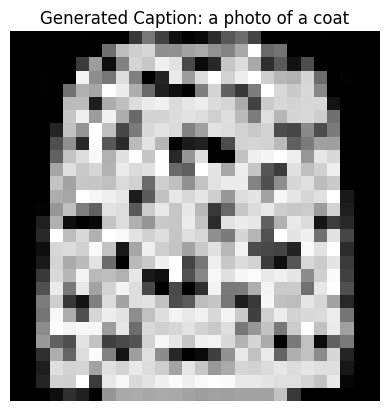

Generated Caption: a photo of a coat
Actual Template Caption: startseq an image containing a pullover endseq


In [7]:
def generate_caption(image):
    seq = [tokenizer.word_index["startseq"]]

    for _ in range(max_len):
        padded = pad_sequences(
            [seq], maxlen=max_len, padding="post"
        )

        pred = model.predict(
            [np.expand_dims(image, axis=0), padded],
            verbose=0
        )

        next_id = int(np.argmax(pred[0]))
        word = tokenizer.index_word.get(next_id, "<unk>")

        if word == "endseq":
            break

        seq.append(next_id)

    words = [
        tokenizer.index_word.get(i, "<unk>")
        for i in seq
        if i != tokenizer.word_index["startseq"]
    ]

    return " ".join(words)


idx = 0
image = test_images[idx]
caption = generate_caption(image)

plt.imshow(image.squeeze(), cmap="gray")
plt.axis("off")
plt.title("Generated Caption: " + caption)
plt.show()

print("Generated Caption:", caption)
print("Actual Template Caption:", test_captions[idx])